Projet ML partie Baptiste

On commence par la partie regression logistique

In [2]:
import numpy as np
import pandas as pd

from pathlib import Path
fichier = Path("/Users/baptistejacquet/Desktop/Projet_ML/ecoli_ciprofloxacin.csv")
print(fichier.exists())

True


In [3]:
# On lit d'abord seulement l'en-tête pour connaître les colonnes
noms_colonnes = pd.read_csv(fichier, nrows=0).columns
  
# Les 4 premières colonnes décrivent le génome, toutes les autres sont des gènes (0/1)
colonnes_info = ["sra", "Genome.Name", "mlst_group", "y"]
  
# On force le type : int8 pour les gènes (sinon le fichier prend trop de mémoire)
types = {c: "int8" for c in noms_colonnes if c not in colonnes_info}
types.update({"sra": str, "Genome.Name": str, "mlst_group": str, "y": "int8"})
 
data = pd.read_csv(fichier, dtype=types)
print("dimensions :", data.shape)

dimensions : (5935, 20735)


VERIFICATION DU JEU DE DONNEES

In [4]:
# Valeurs manquantes (on attend 0)
print("valeurs manquantes :", data.isna().sum().sum())

# Répartition de la variable réponse y (1 = résistant à la ciprofloxacine)
print(data["y"].value_counts())
print(f"proportion de résistants : {data['y'].mean():.3f}")

# Les gènes ne doivent contenir que des 0 et des 1
genes = data.drop(columns=colonnes_info)
print("valeurs des gènes :", sorted(pd.unique(genes.values.ravel())))
print("nombre de gènes :", genes.shape[1])

valeurs manquantes : 0
y
0    4650
1    1285
Name: count, dtype: int64
proportion de résistants : 0.217
valeurs des gènes : [np.int8(0), np.int8(1)]
nombre de gènes : 20731


On va selectionner et separer nos variables reponses et explicatives
Saud que ici, sur nos 5935 souches, on a 406 individus qui veinnet de souche unkownk, donc ici on les traite comme des individus ayant leur propre ligné ce qui fait qu'on a 422 + 406 = 828 lignés.

In [5]:
# X : les gènes (variables explicatives)
X = data.drop(columns=colonnes_info)
  
# y : variable réponse (1 = résistant)
y = data["y"]
  
# groups : la lignée de chaque génome. Les "unknown" ne forment pas une vraie lignée :
# on donne à chacun son propre groupe pour ne pas créer un bloc artificiel de 406 génomes
groups = data["mlst_group"].where(data["mlst_group"] != "unknown", "unknown_" + data["sra"])
  
print("X :", X.shape)
print("y :", y.shape)
print("nombre de lignées :", groups.nunique())
data.loc[data["mlst_group"] != "unknown", "mlst_group"].value_counts().head(10)

X : (5935, 20731)
y : (5935,)
nombre de lignées : 828


mlst_group
ST131    739
ST73     724
ST95     518
ST69     378
ST12     193
ST127    160
ST10     146
ST141     98
ST59      94
ST58      83
Name: count, dtype: int64

passe au découpage entre train et test or 
- on voit qu'on a des proportion très inégales du nombre de souche pour chaque lignés
- les souches d'une meme ligné ont des gènes très similaire (donc forte corrélation)
Donc pour le décupage attention a bien mettre les individus proche ensmebnle car si on train et test sur des indvidus différent mais qui se ressemble beaucoup on a un effet de biais comme si on avait pas deocuper notre jeu de données

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

# 4 parts => on garde 1 part pour le test (25 %) et 3 pour l'entraînement (75 %) comme dans cours Emilie
# Chaque lignée est entièrement d'un côté ou de l'autre, et on garde à peu près la même proportion de y
decoupage = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
idx_train, idx_test = next(decoupage.split(X, y, groups))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
groups_train = groups.iloc[idx_train]

print("train :", X_train.shape, "| test :", X_test.shape)
print(f"résistants train : {y_train.mean():.3f} | test : {y_test.mean():.3f}")
print("lignées communes train/test :", len(set(groups.iloc[idx_train]) & set(groups.iloc[idx_test])))

train : (4777, 20731) | test : (1158, 20731)
résistants train : 0.210 | test : 0.242
lignées communes train/test : 0


On passe ensuite au choix du modèle donc on fait un regresio logistique pour se familiariser

In [23]:
lr_mod_lasso = LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", max_iter=1000)  # L1 Lasso
lr_mod_ridge = LogisticRegression(penalty="l2", solver="liblinear", class_weight="balanced", max_iter=1000)  # L2 Ridge
print(lr_mod_lasso)
print(lr_mod_ridge)

LogisticRegression(class_weight='balanced', max_iter=1000, penalty='l1',
                   solver='liblinear')
LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')


Dans notre modèle les valeurs valent deja entre 0 et 1 donc pas beoisn de normalisation, on passe directement a notre workflow qui va nous servir pour plus tard si on veut modifier nos boite

In [27]:
from sklearn.pipeline import Pipeline

# Workflow = prétraitement + modèle assemblés en un seul objet
# Ici le prétraitement est vide (gènes déjà en 0/1), il n'y a donc qu'une étape : le modèle
wf_lasso = Pipeline([("modele", lr_mod_lasso)])
wf_ridge = Pipeline([("modele", lr_mod_ridge)])

print(wf_lasso)
print(wf_ridge)

Pipeline(steps=[('modele',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    penalty='l1', solver='liblinear'))])
Pipeline(steps=[('modele',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    solver='liblinear'))])


Code ci dessous excuté en quelques minutes: 

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
#
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Valeurs de penalité à essayer (équivalent du tune_grid)
grille = {"modele__C": [0.001, 0.01, 0.1, 1]}

recherches = {}
for nom, wf in [("lasso", wf_lasso), ("ridge", wf_ridge)]:
    recherche = GridSearchCV(wf, grille, cv=folds, scoring="roc_auc", n_jobs=3)
    recherche.fit(X_train, y_train, groups=groups_train)   # groups : pour découper par lignée
    recherches[nom] = recherche
    print(f"{nom} : meilleur C = {recherche.best_params_['modele__C']}, "
          f"AUC en validation croisée = {recherche.best_score_:.3f}")

lasso : meilleur C = 0.1, AUC en validation croisée = 0.892
ridge : meilleur C = 0.01, AUC en validation croisée = 0.903


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

for nom, pen, C in [("ridge", "l2", 0.01), ("lasso", "l1", 0.1)]:
    m = LogisticRegression(penalty=pen, solver="liblinear", C=C, class_weight="balanced", max_iter=1000).fit(Xtr, ytr)
    print(nom)
    print(confusion_matrix(yte, m.predict(Xte)))

ridge
[[845  33]
 [ 69 211]]
lasso
[[819  59]
 [ 58 222]]


Partie MLP pour comaprer

In [7]:
# Cellule A : données au format attendu par le MLP
Xtr = X_train.to_numpy(dtype="float32")   # gènes en nombres décimaux (32 bits suffisent)
ytr = y_train.to_numpy()                  # 0 = sensible, 1 = résistant
gtr = groups_train.to_numpy()             # la lignée de chaque génome (pour la validation par lignée)

print(Xtr.shape, ytr.mean().round(3))

(4777, 20731) 0.21


In [8]:
# Cellule B : un premier MLP, entraîné une seule fois
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

# 1) Examen blanc : on met de côté des lignées entières, à l'intérieur du train
i_in, i_val = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(Xtr, ytr, gtr))

# 2) Le panneau de 64 lampes (une seule couche cachée)
mlp = MLPClassifier(hidden_layer_sizes=(64,), random_state=0)

# 3) On règle les molettes sur les « annales » seulement
mlp.fit(Xtr[i_in], ytr[i_in])

# 4) On mesure sur ce qu'il a vu, puis sur des lignées nouvelles
auc_vus     = roc_auc_score(ytr[i_in],  mlp.predict_proba(Xtr[i_in])[:, 1])
auc_nouveau = roc_auc_score(ytr[i_val], mlp.predict_proba(Xtr[i_val])[:, 1])
print("passages :", mlp.n_iter_, "| AUC génomes vus :", round(auc_vus, 3), "| AUC lignées nouvelles :", round(auc_nouveau, 3))

/Users/baptistejacquet/Library/Python/3.9/lib/python/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


passages : 200 | AUC génomes vus : 0.997 | AUC lignées nouvelles : 0.927


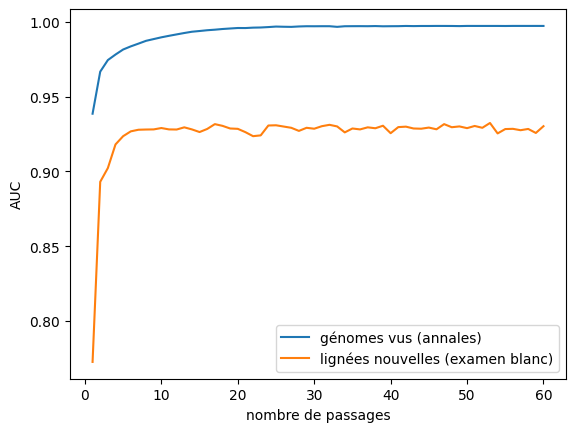

meilleur passage : 53 | AUC : 0.932


In [10]:
# Cellule C : la courbe d'entraînement, passage par passage
import numpy as np
import matplotlib.pyplot as plt

mlp = MLPClassifier(hidden_layer_sizes=(64,), random_state=0)   # panneau neuf
passages, auc_vus, auc_nouveau = [], [], []

for p in range(1, 61):                                                  # 60 leçons
    mlp.partial_fit(Xtr[i_in], ytr[i_in], classes=np.array([0, 1]))    # UN passage
    passages.append(p)
    auc_vus.append(roc_auc_score(ytr[i_in],  mlp.predict_proba(Xtr[i_in])[:, 1]))
    auc_nouveau.append(roc_auc_score(ytr[i_val], mlp.predict_proba(Xtr[i_val])[:, 1]))

plt.plot(passages, auc_vus, label="génomes vus (annales)")
plt.plot(passages, auc_nouveau, label="lignées nouvelles (examen blanc)")
plt.xlabel("nombre de passages"); plt.ylabel("AUC"); plt.legend(); plt.show()
print("meilleur passage :", passages[int(np.argmax(auc_nouveau))], "| AUC :", round(max(auc_nouveau), 3))

In [11]:
# Cellule D : choisir la taille du panneau et le frein alpha
import warnings
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)   # mêmes plis que ta régression
grille = {"hidden_layer_sizes": [(16,), (64,)],
          "alpha": [0.01, 1, 10]}

mlp = MLPClassifier(max_iter=30, random_state=0)   # 30 passages : la courbe C était plate après ~10
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                # cache l'avertissement « pas convergé » (voulu)
    recherche_mlp = GridSearchCV(mlp, grille, cv=folds, scoring="roc_auc", n_jobs=1)
    recherche_mlp.fit(Xtr, ytr, groups=gtr)

res = pd.DataFrame(recherche_mlp.cv_results_)[["param_hidden_layer_sizes", "param_alpha", "mean_test_score", "std_test_score"]]
print(res.sort_values("mean_test_score", ascending=False).round({"mean_test_score": 3, "std_test_score": 3}).to_string(index=False))
print("meilleur :", recherche_mlp.best_params_, round(recherche_mlp.best_score_, 3))

param_hidden_layer_sizes  param_alpha  mean_test_score  std_test_score
                   (64,)        10.00            0.911           0.067
                   (16,)        10.00            0.910           0.082
                   (64,)         1.00            0.908           0.076
                   (16,)         1.00            0.907           0.082
                   (16,)         0.01            0.902           0.069
                   (64,)         0.01            0.892           0.073
meilleur : {'alpha': 10, 'hidden_layer_sizes': (64,)} 0.911


In [16]:
# Cellule E : évaluation finale sur le test (une seule fois)
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

Xte = X_test.to_numpy(dtype="float32")     # le test sort du coffre
yte = y_test.to_numpy()

# 1) MLP avec les réglages choisis, 5 graines (le hasard initial des molettes change)
scores_mlp = []
for graine in range(5):
    m = MLPClassifier(hidden_layer_sizes=(16,), alpha=10, max_iter=30, random_state=graine)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    scores_mlp.append((roc_auc_score(yte, p), average_precision_score(yte, p)))
scores_mlp = np.array(scores_mlp)
print(f"MLP (16 neurones, alpha=10) : AUC {scores_mlp[:, 0].mean():.3f} ± {scores_mlp[:, 0].std():.3f}"
      f" | AP {scores_mlp[:, 1].mean():.3f} ± {scores_mlp[:, 1].std():.3f}")

MLP (16 neurones, alpha=10) : AUC 0.951 ± 0.002 | AP 0.885 ± 0.007


In [13]:
# Cellule E bis : ridge et lasso avec les C trouvés par ta validation croisée
from sklearn.linear_model import LogisticRegression

for nom, penalite, C in [("ridge", "l2", 0.01), ("lasso", "l1", 0.1)]:
    lr = LogisticRegression(penalty=penalite, solver="liblinear", C=C,
                            class_weight="balanced", max_iter=1000)
    lr.fit(Xtr, ytr)                                   # mêmes données que le MLP
    p = lr.predict_proba(Xte)[:, 1]
    print(f"{nom} (C={C}) : AUC {roc_auc_score(yte, p):.3f} | AP {average_precision_score(yte, p):.3f}")

ridge (C=0.01) : AUC 0.947 | AP 0.858
lasso (C=0.1) : AUC 0.939 | AP 0.855


Sur le jeu de test, le MLP à 16 neurones fait un peu mieux que la ridge (AUC 0,951 contre 0,947, AP 0,885 contre 0,858), mais le gain est faible. Une régression ridge, beaucoup plus simple, interprétable et déterministe, est presque aussi bonne. Le signal des gènes semble donc surtout additif, et la complexité du réseau n’apporte presque rien